# 03 &nbsp;How many labelled examples does fine-tuning need to catch up?

**The problem.** Labels cost money and time. Notebook 02 showed that with all 9,000 labelled examples the fine-tuned small model is the most accurate option, and that with only 5 per intent it is the least accurate. A team needs to know where in between it pays to fine-tune, and how much they risk if they stop early.

**The approach.**

1. Train each small model on 5, 10, 25 and 50 labelled examples per intent and on all of them, three random draws each. The sets are nested: the 10 per intent include the 5, so the curve shows the value of more labels rather than the luck of a new draw.
2. Put the prompted models on the same axis. Examples in a prompt are labels too: 5 per intent in the prompt is 385 labelled messages, the same 385 the small models trained on in their first draw.
3. Find the size at which fine-tuning passes each other option, using paired differences on the same test messages.

Each model's settings were picked once on a validation set held out from training and then used at every size. Haiku answered all 3,080 test messages; Sonnet answered 20 per intent (1,540).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from fopstudy import plots, style
from fopstudy.evaluate import learning_curve_summary, paired_difference
from fopstudy.results import RESULTS_DIR, correctness

style.use_style()
curves = {a: learning_curve_summary(a) for a in style.APPROACH_ORDER}
SIZES = [5, 10, 25, 50, "all"]
SEEDS = {"frozen": {n: (0, 1, 2) for n in SIZES[:-1]} | {"all": (0,)},
         "finetuned": {n: (0, 1, 2) for n in SIZES}}
overview = pd.concat(curves.values()).pivot(index="n_per_class", columns="approach", values="accuracy")
overview = overview[style.APPROACH_ORDER].rename(columns=style.APPROACH_LABELS).rename_axis(
    index="Labelled examples per intent", columns=None)
overview.style.format("{:.1%}", na_rep="")

,"Small model, not fine-tuned","Small model, fine-tuned","Claude Haiku 5.5, prompted","Claude Sonnet 5.5, prompted"
Labelled examples per intent,,,,
0,,,79.7%,84.0%
1,,,82.8%,87.3%
5,83.1%,65.4%,87.2%,89.9%
10,87.2%,78.8%,,
25,90.2%,87.9%,,
50,91.8%,91.5%,,
all,92.8%,93.5%,,


## 1. The learning curves

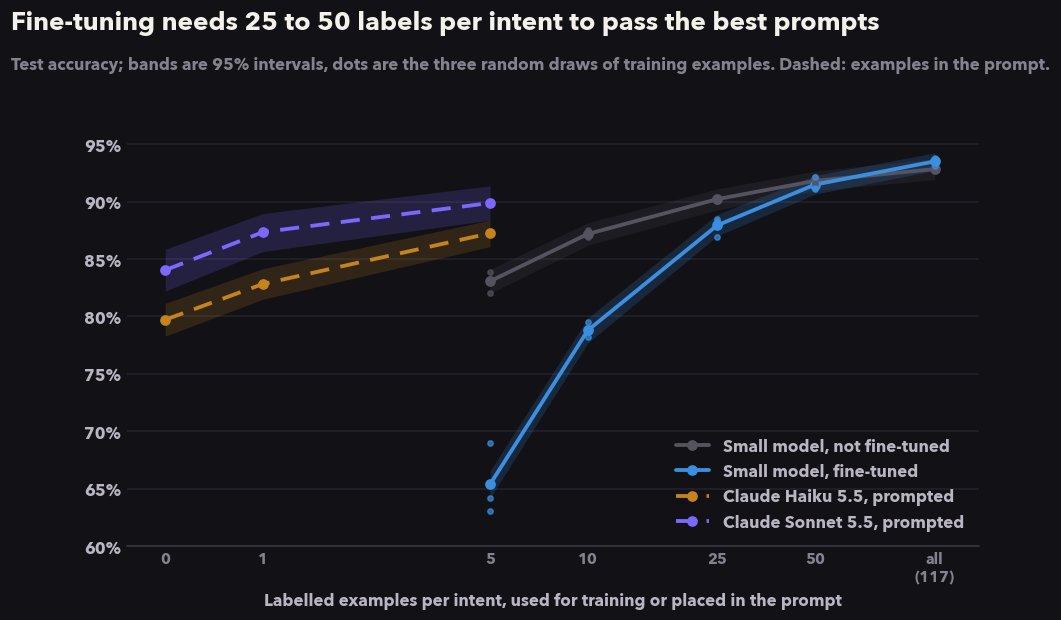

In [2]:
ft = curves["finetuned"].set_index("n_per_class")["accuracy"]
haiku5 = curves["haiku"].set_index("n_per_class").loc[5, "accuracy"]
sonnet5 = curves["sonnet"].set_index("n_per_class").loc[5, "accuracy"]
passes = lambda target: next(n for n in SIZES if ft[n] > target)

fig, ax = plots.learning_curve([curves[a] for a in style.APPROACH_ORDER], label_last=False)
ax.set_ylim(0.6, 0.97)
ax.set_xlim(0.38, 160)
ax.set_xlabel("Labelled examples per intent, used for training or placed in the prompt")
handles = [Line2D([], [], color=style.APPROACH_COLORS[a], linewidth=2.5, marker="o",
                  linestyle=(0, (5, 3)) if a in style.PROMPTED else "-") for a in style.APPROACH_ORDER]
ax.legend(handles, [style.APPROACH_LABELS[a] for a in style.APPROACH_ORDER], loc="lower right")
fig.subplots_adjust(top=0.80)
style.headline(fig, f"Fine-tuning needs {passes(haiku5)} to {passes(sonnet5)} labels per intent "
                    f"to pass the best prompts",
               "Test accuracy; bands are 95% intervals, dots are the three random draws of training examples. "
               "Dashed: examples in the prompt.")
style.save(fig, "learning_curves")

Three things stand out:

- **Fine-tuning starts far behind.** With 5 labelled examples per intent, fine-tuning a 150M-parameter model gets about two in three right, worse than both prompted models with *no* examples at all.
- **It climbs steeply.** Each step from 5 to 50 per intent adds more for the fine-tuned model than for any other option, so it overtakes the prompts somewhere between 10 and 50 per intent.
- **The model that was not fine-tuned is there first.** The frozen embeddings with a linear classifier start high and stay high; it matches Haiku's five-example prompt at about 10 per intent.

## 2. Fine-tuned against not fine-tuned, at every size

Both small models were trained on exactly the same examples at each size and draw, so the difference below isolates what fine-tuning the whole model adds over training only a classifier on frozen embeddings. Each message's correctness is averaged over the three draws before the difference is taken.

,Difference,95% low,95% high
Labelled examples per intent,,,
5 per intent,-17.7 pts,-18.7 pts,-16.7 pts
10 per intent,-8.4 pts,-9.2 pts,-7.5 pts
25 per intent,-2.3 pts,-2.9 pts,-1.6 pts
50 per intent,-0.3 pts,-0.9 pts,+0.3 pts
all (117),+0.7 pts,-0.0 pts,+1.4 pts


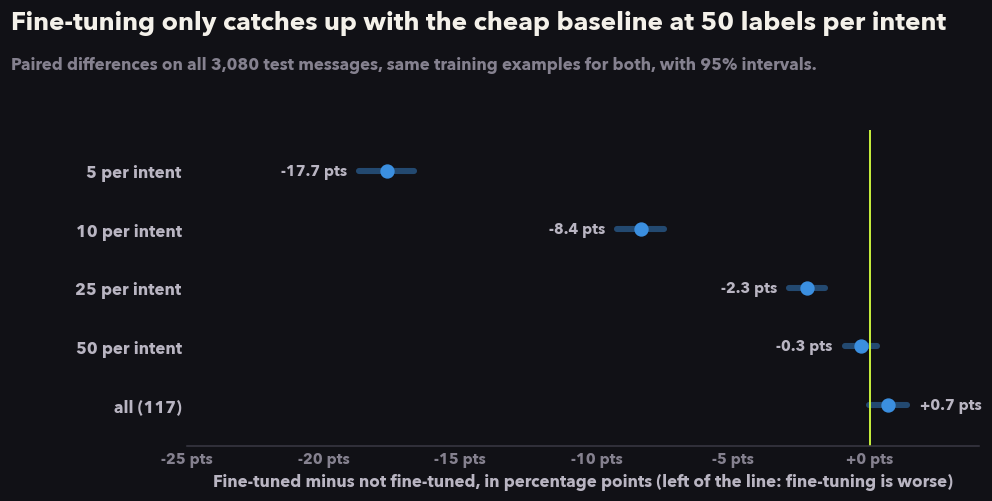

In [3]:
rows = []
for n in SIZES:
    d = paired_difference(correctness("finetuned", n, SEEDS["finetuned"][n]),
                          correctness("frozen", n, SEEDS["frozen"][n]))
    rows.append({"label": "all (117)" if n == "all" else f"{n} per intent", "value": d[0], "low": d[1], "high": d[2],
                 "colour": style.APPROACH_COLORS["finetuned"]})
gap = pd.DataFrame(rows)

fig, ax = plots.dot_intervals(gap, value_format=lambda v: f"{v * 100:+.1f} pts")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:+.0f} pts"))
ax.set_xlabel("Fine-tuned minus not fine-tuned, in percentage points (left of the line: fine-tuning is worse)")
ax.set_xlim(-0.25, 0.04)
fig.subplots_adjust(top=0.74, left=0.18)
style.headline(fig, "Fine-tuning only catches up with the cheap baseline at 50 labels per intent",
               "Paired differences on all 3,080 test messages, same training examples for both, with 95% intervals.")
style.save(fig, "finetuned_minus_frozen")
gap[["label", "value", "low", "high"]].set_index("label").rename_axis("Labelled examples per intent").rename(
    columns={"value": "Difference", "low": "95% low", "high": "95% high"}).style.format(lambda v: f"{v * 100:+.1f} pts")

With all labels the fine-tuned model is ahead by under a point, and the interval reaches zero. On this task, fine-tuning the whole model never clearly beats training a classifier on frozen embeddings, which takes about a second on a laptop CPU instead of 14 minutes on its GPU.

## 3. At which size does fine-tuning pass each prompt?

The same paired comparison against the best prompt for each hosted model: Haiku on all 3,080 messages, Sonnet on the 1,540 it answered.

In [4]:
h5, s5 = correctness("haiku", 5), correctness("sonnet", 5)
table = {}
for n in SIZES:
    c = correctness("finetuned", n, SEEDS["finetuned"][n])
    table[n] = {**dict(zip(["Haiku: difference", "Haiku: low", "Haiku: high"], paired_difference(c, h5))),
                **dict(zip(["Sonnet: difference", "Sonnet: low", "Sonnet: high"], paired_difference(c.loc[s5.index], s5)))}
vs_prompt = pd.DataFrame(table).T
vs_prompt.index.name = "Labelled examples per intent (fine-tuned)"
vs_prompt.style.format(lambda v: f"{v * 100:+.1f} pts")

,Haiku: difference,Haiku: low,Haiku: high,Sonnet: difference,Sonnet: low,Sonnet: high
Labelled examples per intent (fine-tuned),,,,,,
5,-21.9 pts,-23.2 pts,-20.5 pts,-24.3 pts,-26.0 pts,-22.5 pts
10,-8.5 pts,-9.6 pts,-7.2 pts,-11.5 pts,-13.1 pts,-10.0 pts
25,+0.7 pts,-0.4 pts,+1.8 pts,-2.5 pts,-3.9 pts,-1.1 pts
50,+4.2 pts,+3.2 pts,+5.3 pts,+1.4 pts,+0.0 pts,+2.8 pts
all,+6.3 pts,+5.2 pts,+7.3 pts,+3.4 pts,+2.1 pts,+4.7 pts


In [5]:
clear = lambda col: next((n for n in SIZES if vs_prompt.loc[n, f"{col}: low"] > 0), "never")
print(f"Fine-tuning is clearly ahead (interval above zero) of Haiku with 5 examples from {clear('Haiku')} "
      f"labels per intent, and of Sonnet with 5 examples from {clear('Sonnet')}.")

Fine-tuning is clearly ahead (interval above zero) of Haiku with 5 examples from 50 labels per intent, and of Sonnet with 5 examples from 50.


## 4. How much the result depends on the draw, and what training costs

A team only gets one draw of examples to label. At small sizes, which examples were drawn moves the fine-tuned model's accuracy by several points; the frozen model is far steadier.

In [6]:
runs_ft = pd.read_csv(RESULTS_DIR / "runs_finetuned.csv")
runs_fz = pd.read_csv(RESULTS_DIR / "runs_frozen.csv")
spread = pd.DataFrame({
    "Fine-tuned: worst draw": curves["finetuned"].set_index("n_per_class")["seed_accuracies"].map(min),
    "Fine-tuned: best draw": curves["finetuned"].set_index("n_per_class")["seed_accuracies"].map(max),
    "Not fine-tuned: worst draw": curves["frozen"].set_index("n_per_class")["seed_accuracies"].map(min),
    "Not fine-tuned: best draw": curves["frozen"].set_index("n_per_class")["seed_accuracies"].map(max),
})
# The first fine-tuning draw shared the GPU with another job and ran slower, so times come from draws 2 and 3.
spread["Fine-tuning time (minutes)"] = (runs_ft[runs_ft["seed"] > 0].groupby(runs_ft["n_per_class"].astype(str))
                                        ["train_seconds"].mean() / 60).reindex(spread.index.astype(str)).to_numpy()
spread["Classifier training time (seconds)"] = (runs_fz.groupby(runs_fz["n_per_class"].astype(str))
                                               ["train_seconds"].mean()).reindex(spread.index.astype(str)).to_numpy()
spread.index.name = "Labelled examples per intent"
spread.style.format({c: "{:.1%}" for c in spread.columns[:4]} | {spread.columns[4]: "{:.0f}", spread.columns[5]: "{:.2f}"})

,Fine-tuned: worst draw,Fine-tuned: best draw,Not fine-tuned: worst draw,Not fine-tuned: best draw,Fine-tuning time (minutes),Classifier training time (seconds)
Labelled examples per intent,,,,,,
5,63.0%,69.0%,82.1%,83.9%,6,0.09
10,78.2%,79.5%,86.9%,87.5%,6,0.13
25,86.9%,88.5%,90.0%,90.3%,7,0.23
50,91.1%,92.1%,91.6%,92.2%,7,0.44
all,93.1%,93.8%,92.8%,92.8%,14,1.37


Fine-tuning times are on an Apple M4 laptop GPU, with at least 500 training steps at every size (so the small sets are seen many times over). The frozen model's times leave out embedding the messages once, which takes about a minute for the whole training set and is shared by every size.

## 5. Could better tuning rescue the small sizes?

The fine-tuning learning rate was picked once, as the best average validation accuracy at 10 and 50 examples per intent. The highest rate in the grid won on average, though at 50 per intent a lower rate did slightly better. Tuning the rate separately for each size might lift the smallest sizes a little, but a team with 5 labels per intent has no spare labels to tune on, and the gap to the frozen model at 5 per intent (about 18 points) is far larger than the tuning differences below.

In [7]:
tuning = pd.read_csv(RESULTS_DIR / "tuning_finetuned.csv").pivot(index="lr", columns="n_per_class", values="val_acc")
tuning.columns = [f"Validation accuracy, {n} per intent" for n in tuning.columns]
tuning.index = tuning.index.map(lambda v: f"{v:g}")
tuning.index.name = "Learning rate"
tuning.style.format("{:.1%}")

,"Validation accuracy, 10 per intent","Validation accuracy, 50 per intent"
Learning rate,,
5e-05,71.5%,88.5%
0.0001,76.0%,90.5%
0.0002,79.9%,89.4%


## What this means

- **Below about 25 labels per intent, do not fine-tune.** A prompted model, or a classifier on frozen embeddings, is more accurate and needs no training run.
- **Fine-tuning passes the prompts with a few thousand labels.** It draws level with Haiku's best prompt at 25 per intent (about 1,900 labels) and is ahead of both from 50 (about 3,800), clearly ahead of Haiku but only just ahead of Sonnet.
- **But it only ties the model that was not fine-tuned.** At every size, training a linear classifier on frozen embeddings is better or within a point. On this task, the case for the small model is a case for the cheap version of it; fine-tuning adds under a point with all labels.
- **Small label sets are a gamble for fine-tuning.** At 5 per intent, which 385 examples happened to be labelled moves fine-tuned accuracy by about 6 points.

**What the data can't tell us.** Each prompted model was run once, with 0, 1 and 5 examples per intent; more examples in the prompt might keep improving it, at a higher cost per request (notebook 04). Results come from one 150M-parameter model with one learning rate for all sizes; a larger model, or a different training recipe, could catch up sooner. And this is one task with 77 fairly clear-cut intents.